In [1]:
# --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. ---
# Z3ST: An open-source FEniCSx framework for thermo-mechanical analysis
# Author: Bianca Funaro
# Version: 0.4.1 (2026)
# --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. ---

# IAEA VP1, step 1: radial $\Delta T$ only, uniform in $z$

First step towards the IAEA VP1 benchmark (hexagonal 15-15Ti duct, 4 m, base clamped). The axial ramp of VP1 is
switched off: the core-top section is imposed over the whole height,
$$T(y) = 525 - 333.3\,y \quad (^\circ\text{C},\ y \text{ in m}),$$
i.e. the axial shape factor is $f(z) \equiv 1$ (`Z_UNIFORM = True` in `vp1_temperature.py`). $T$ is linear across the
section, from the hot corner (550 °C, $y = -0.075$ m) to the cold corner (500 °C, $y = +0.075$ m).

This is the "clean" limit of section 2 of `T_asymmetries/asymmetric_T_free_duct.ipynb`: $T$ *is* a plane, so the
whole thermal strain is absorbed by elongation and bending, and no stress is left away from the base.

**Boundary conditions** (`boundary_conditions.yaml`):

| | thermal | mechanical |
|---|---|---|
| whole body | model off, $T$ imposed as eigenstrain $\alpha\,(T - T_{ref})\,\mathbf I$ | |
| bottom, $z = 0$ | | `Clamp_x`, `Clamp_y`, `Clamp_z` ($\mathbf u = \mathbf 0$, as MOOSE VP1) |
| flats, top | | free |

Material (`15_15Ti_local.yaml`, VP1 values): $E$ = 170 GPa, $\nu$ = 0.3, $\alpha = 18\cdot10^{-6}$ 1/K,
$T_{ref}$ = 400 °C. Geometry (`geometry.yaml`): corner-to-corner depth at mid-wall $D$ = 0.150 m, $t$ = 3 mm,
$H$ = 4 m, corners on $\pm y$ (`orientation: vertical`). Mesh: Q1 hexahedra, `nf` 8, `nt` 1, `nz` 400
(element height 10 mm). Gravity off.

All numbers are read from `output/vp1_step1_fields_3d.xdmf`.

> **How to read this notebook.** Each section gives the closed-form expectation, the values recorded from the
> stored run, and a code cell that recomputes them from `output/`. Run the code cells only when no z3st run is
> writing `output/vp1_step1_fields_3d.h5`.

In [2]:
import os

os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

import h5py                                                   # noqa: E402
import matplotlib.pyplot as plt                               # noqa: E402
import numpy as np                                            # noqa: E402

import vp1_temperature as vt                                  # noqa: E402
from z3st.utils.utils_extract_xdmf import extract_field_xdmf  # noqa: E402

E, NU, ALPHA, T_REF = 1.7e11, 0.3, 1.8e-5, 400.0     # 15_15Ti_local.yaml, T_ref in degC
EA = E * ALPHA / 1e6                                 # (MPa/K)
D = vt.D                                             # (m) corner-to-corner depth at mid-wall

XDMF = os.path.join("output", "vp1_step1_fields_3d.xdmf")
with h5py.File(XDMF.replace(".xdmf", ".h5"), "r") as f:
    P = np.array(f["Mesh/mesh/geometry"])
    TOPO = np.array(f["Mesh/mesh/topology"])
U = extract_field_xdmf(XDMF, "Displacement", -1, return_coords=False)
S = extract_field_xdmf(XDMF, "Stress", -1, return_coords=False).reshape(-1, 3, 3) / 1e6   # (MPa), per cell
C = P[TOPO].mean(axis=1)                              # cell centres
H = np.ptp(P[:, 2])
zs = np.unique(np.round(P[:, 2], 9))                  # node layers
zc = np.unique(np.round(C[:, 2], 9))                  # cell layers

# Local frame of the flats: outward normals at A0 + 30 + 60 m deg, A0 = corner angle mod 60
r = np.hypot(P[:, 0], P[:, 1])
A0 = np.arctan2(P[np.argmax(r), 1], P[np.argmax(r), 0]) % (np.pi / 3)
PHI_N = A0 + np.pi / 6 + np.arange(6) * np.pi / 3
A_OUT = r.max() * np.cos(np.pi / 6)                   # outer apothem


def frame(phi):
    n = np.array([np.cos(phi), np.sin(phi), 0.0])
    return n, np.array([-n[1], n[0], 0.0])


def mid_flat_cells(phi, layer):
    # cells of one flat (normal phi) within 6 mm of mid-flat, in a cell layer
    n, s = frame(phi)
    return layer & (np.abs(C @ s) < 0.006) & (C @ n > 0.9 * A_OUT)


def T_degC(p):
    return vt.T_vp1(p.T) - 273.15


print(f"D = {D:.4f} m, H = {H:.2f} m, {len(TOPO)} cells, {len(zs)} node layers")
print("flat normals (deg):", np.round(np.degrees(PHI_N) % 360).astype(int), "  Z_UNIFORM =", vt.Z_UNIFORM)

D = 0.1500 m, H = 4.00 m, 19200 cells, 401 node layers
flat normals (deg): [ 60 120 180 240 300   0]   Z_UNIFORM = True


## 1. Imposed temperature and closed-form expectations

With $f \equiv 1$ the temperature is the same at every height and linear across the section,
$$T = T_0 + c_y\,y, \qquad T_0 = 525\ ^\circ\text{C}, \qquad c_y = -\frac{\Delta T}{D} = -\frac{50}{0.15} = -333.3\ \text{K/m}.$$
A linear $T$ produces a compatible thermal strain field: the duct can follow it without stress, as a circular arc
plus a uniform elongation. Beam kinematics ($u_y = \kappa z^2/2$, $u_z = -\kappa\,y\,z$,
$\varepsilon_{zz} = \varepsilon_0 - \kappa\,y$) matched to $\varepsilon_{zz} = \alpha\,(T - T_{ref})$ give

| quantity | formula | value |
|---|---|---|
| curvature | $\kappa = -\alpha\,c_y = \alpha\,\Delta T / D$ | $18\cdot10^{-6}\cdot 50/0.15 = 6.0\cdot10^{-3}$ 1/m |
| deflection (cantilever) | $w(z) = \kappa z^2/2$ | 18.75 mm at 2.5 m, 48.0 mm at the tip (4 m) |
| elongation | $\Delta H = \alpha\,(T_0 - T_{ref})\,H$ | $18\cdot10^{-6}\cdot 125\cdot 4 = 9.0$ mm |
| stress | $\sigma_{zz} = -E\alpha\,(T - T_{plane})$ | 0 (away from the base) |

The base clamp is compatible with the bow: $u_y = \kappa z^2/2$ and $u_z = -\kappa y z$ both vanish at $z = 0$,
together with the slope. The hot side is at $y < 0$ and expands more, so the duct is convex towards the hot corner
and the tip moves towards the cold corner ($+y$).

### Small displacements

z3st is geometrically linear: strains $\tfrac12(\nabla\mathbf u + \nabla\mathbf u^T)$ and equilibrium on the
undeformed configuration. Switching the ramp off does not change that, and it does not need to: the largest
rotation is at the tip, $\theta = \kappa H = 0.024$ rad, with $w/H$ = 1.2 %. The exact arc gives
$w = (1 - \cos\kappa z)/\kappa \approx \kappa z^2/2\,\big(1 - (\kappa z)^2/12\big)$: the linear theory is high by
$(\kappa H)^2/12 = 5\cdot10^{-5}$ in relative terms, 2 µm at the tip. There is no axial load, so no $P$-$\delta$
effect either. The thermal strain itself is $\alpha\,(T - T_{ref}) \approx 2.3\cdot10^{-3}$. The small-strain,
small-displacement hypothesis holds.

In [3]:
print(f"{'flat (deg)':>10s} {'y mid-flat (m)':>15s} {'T (degC)':>9s}")
for phi in PHI_N:
    p = np.array([[A_OUT * np.cos(phi), A_OUT * np.sin(phi), z] for z in (0.0, H / 2, H)])
    t = T_degC(p)
    print(f"{np.degrees(phi) % 360:10.0f} {p[0, 1]:15.4f} {t[0]:9.2f}   spread along z {np.ptp(t):.1e} K")
corners = np.array([[0.0, -D / 2, 1.0], [0.0, D / 2, 1.0]])
print("hot / cold corner at mid-wall (degC):", np.round(T_degC(corners), 2))

kappa = ALPHA * 50.0 / D
w = lambda z: kappa * z**2 / 2
dH = ALPHA * (525.0 - T_REF) * H
print(f"\nkappa = {kappa:.4e} 1/m,  w(2.5) = {w(2.5) * 1e3:.2f} mm,  w(4) = {w(H) * 1e3:.2f} mm,  dH = {dH * 1e3:.2f} mm")
print(f"tip rotation kappa*H = {kappa * H:.4f} rad,  (kappa H)^2/12 = {(kappa * H)**2 / 12:.1e}")

flat (deg)  y mid-flat (m)  T (degC)
        60          0.0575    505.82   spread along z 0.0e+00 K
       120          0.0575    505.82   spread along z 0.0e+00 K
       180          0.0000    525.00   spread along z 0.0e+00 K
       240         -0.0575    544.18   spread along z 0.0e+00 K
       300         -0.0575    544.18   spread along z 0.0e+00 K
         0         -0.0000    525.00   spread along z 0.0e+00 K
hot / cold corner at mid-wall (degC): [550. 500.]

kappa = 6.0000e-03 1/m,  w(2.5) = 18.75 mm,  w(4) = 48.00 mm,  dH = 9.00 mm
tip rotation kappa*H = 0.0240 rad,  (kappa H)^2/12 = 4.8e-05


**Recorded.** Mid-flat outer face: 505.8 °C on the two cold-side flats (60°, 120°), 525.0 °C on the two side
flats (0°, 180°), 544.2 °C on the hot-side flats (240°, 300°); corners at mid-wall 550.0 / 500.0 °C; no variation
along $z$.

## 2. Stresses: $T$ is its own plane

In the notation of `asymmetric_T_free_duct.ipynb`, section 2, the temperature splits into its best-fit plane and a
remainder, $T = T_{plane} + \Delta T$, and only the remainder is locked in:
$$\sigma_{zz} = -E\,\alpha\,\big(T - T_{plane}\big).$$
Here $T$ coincides exactly with $T_{plane}$, so $\Delta T = 0$ and $\sigma_{zz} = 0$. The in-plane components vanish
too: a linear $T$ in a free body is stress-free in 3D, not only in beam theory. z3st must give $\sigma \approx 0$
everywhere away from the base.

**The base: Saint-Venant.** `Clamp_x`/`Clamp_y` block the in-plane expansion of the bottom section, which would
otherwise grow by $\alpha\,(T - T_{ref})$, i.e. $2.3\cdot10^{-3}$ or about 0.17 mm in radius. Locally the walls are
held at their cold size: the hoop stress tends to
$$\sigma_{ss} \approx -E\alpha\,(T - T_{ref}) \approx -3.06\ \text{MPa/K} \times (T - 400),$$
proportional to the local $T$ (about $-380$ MPa at 525 °C). The disturbance is self-equilibrated and it decays like
the edge layer of a shell clamped at its edge, over a length of the order of
$\lambda = \sqrt{R\,t}\,/\,[3(1-\nu^2)]^{1/4} \approx 12$ mm ($R \approx 0.075$ m): the stresses vanish within a few
$\lambda$, that is within about 0.1 m of the base. A hexagon is not a cylinder, so $\lambda$ gives the order of
magnitude, not a prediction.

In [4]:
def local(A, phi):
    n, s = frame(phi)
    ez = np.array([0.0, 0.0, 1.0])
    return {k: np.einsum("i,cij,j->c", e, A, e) for k, e in (("nn", n), ("ss", s), ("zz", ez))}


dev = S - np.trace(S, axis1=1, axis2=2)[:, None, None] / 3 * np.eye(3)
VM = np.sqrt(1.5 * np.einsum("cij,cij->c", dev, dev))

# T_plane from the cell centres of the mid-height layer: T is exactly linear, so T - T_plane = 0
mid = np.isclose(C[:, 2], zc[np.argmin(np.abs(zc - H / 2))])
M = np.c_[np.ones(mid.sum()), C[mid, 0], C[mid, 1]]
coef = np.linalg.lstsq(M, T_degC(C[mid]), rcond=None)[0]
print(f"T_plane = {coef[0]:.2f} {coef[1]:+.2f} x {coef[2]:+.2f} y   (degC, m);  "
      f"max |T - T_plane| = {np.abs(T_degC(C[mid]) - M @ coef).max():.1e} K\n")

print(f"{'z (m)':>7s} {'max|s_zz|':>10s} {'max|s_ss|':>10s} {'max s_vm':>9s}   sigma_ss at mid-flat (MPa), cold -> hot")
order = np.argsort(np.sin(PHI_N))[::-1]               # cold-side flats (y > 0) first
for z in (zc[0], zc[1], zc[2], zc[3], zc[5], 0.105, 0.205, 1.0, H / 2, 3.0, zc[-1]):
    L = np.isclose(C[:, 2], zc[np.argmin(np.abs(zc - z))])
    ss = [local(S[mid_flat_cells(PHI_N[m], L)], PHI_N[m])["ss"].mean() for m in order]
    print(f"{C[L, 2][0]:7.3f} {np.abs(S[L, 2, 2]).max():10.2f} {np.abs(np.concatenate([local(S[L], p)['ss'] for p in PHI_N])).max():10.2f}"
          f" {VM[L].max():9.2f}   " + " ".join(f"{v:+6.0f}" for v in ss))

L0 = np.isclose(C[:, 2], zc[0])
print("\nfirst cell layer, sigma_ss / (T - T_ref) at mid-flat (MPa/K):",
      np.round([local(S[mid_flat_cells(p, L0)], p)["ss"].mean() / (T_degC(C[mid_flat_cells(p, L0)]).mean() - T_REF)
                for p in PHI_N[order]], 2), f"  (E alpha = {EA:.2f})")

T_plane = 525.00 +0.00 x -333.33 y   (degC, m);  max |T - T_plane| = 2.3e-13 K

  z (m)  max|s_zz|  max|s_ss|  max s_vm   sigma_ss at mid-flat (MPa), cold -> hot
  0.005     152.46     466.19    454.25     -317   -317   -373   -373   -428   -428
  0.015      29.75     238.09    291.87     -177   -177   -207   -207   -237   -237
  0.025      38.75     154.57    150.47     -115   -115   -135   -135   -154   -154
  0.035      53.49      72.24     67.34      -54    -54    -63    -63    -72    -72
  0.055      33.52       3.43     35.05       +0     +0     +0     +0     -0     -0
  0.105       1.48       4.18      5.28       +3     +3     +4     +4     +4     +4
  0.205       0.12       0.47      0.41       -0     -0     -0     -0     -0     -0
  1.005       0.12       0.47      0.41       -0     -0     -0     +0     +0     +0
  1.995       0.12       0.47      0.41       -0     -0     -0     -0     +0     +0
  2.995       0.12       0.47      0.41       -0     -0     -0     +0     +0     +

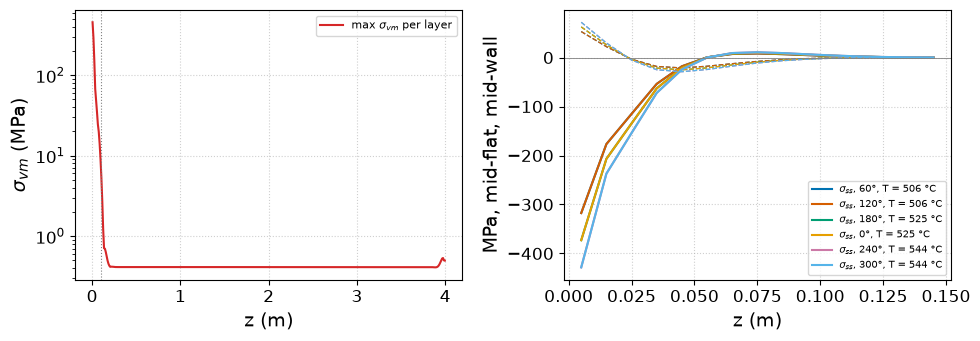

In [5]:
vm_max = np.array([VM[np.isclose(C[:, 2], z)].max() for z in zc])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.semilogy(zc, vm_max, "-", color="tab:red", label=r"max $\sigma_{vm}$ per layer")
ax.axvline(0.1, color="gray", ls=":", lw=0.8)
ax.set_xlabel("z (m)"); ax.set_ylabel(r"$\sigma_{vm}$ (MPa)"); ax.grid(ls=":", alpha=0.6); ax.legend(fontsize=8)
ax.set_title("whole height: the stress is confined to the base")
ax = axes[1]
near = zc < 0.15
for m in order:
    phi = PHI_N[m]
    ss = [local(S[mid_flat_cells(phi, np.isclose(C[:, 2], z))], phi)["ss"].mean() for z in zc[near]]
    zz = [S[mid_flat_cells(phi, np.isclose(C[:, 2], z)), 2, 2].mean() for z in zc[near]]
    y = A_OUT * np.sin(phi)
    lbl = f"{np.degrees(phi) % 360:.0f}°, T = {525 - 333.33 * y:.0f} °C"
    ax.plot(zc[near], ss, "-", label=r"$\sigma_{ss}$, " + lbl)
    ax.plot(zc[near], zz, "--", color=ax.lines[-1].get_color(), lw=0.9)
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("z (m)"); ax.set_ylabel("MPa, mid-flat, mid-wall"); ax.grid(ls=":", alpha=0.6)
ax.set_title(r"base: $\sigma_{ss}$ solid, $\sigma_{zz}$ dashed"); ax.legend(fontsize=7)
fig.tight_layout()

**Recorded.** $T_{plane} = 525.00 - 333.33\,y$ (°C, m), with $|T - T_{plane}| \sim 10^{-13}$ K: $T$ is its own plane.

| z (m) | max $\lvert\sigma_{zz}\rvert$ | max $\sigma_{vm}$ | $\sigma_{ss}$ mid-flat, cold → hot (MPa) |
|---|---|---|---|
| 0.005 (first cell) | 152 | 454 | −317 / −373 / −428 |
| 0.015 | 30 | 292 | −177 / −207 / −237 |
| 0.035 | 53 | 67 | −54 / −63 / −72 |
| 0.055 | 34 | 35 | ≈ 0 ($\sigma_{zz}$ ≈ −18 / −21 / −24) |
| 0.105 | 1.5 | 5.3 | +3 / +4 / +4 |
| 0.2 – 3.0 | 0.12 | 0.41 | ≈ 0 |
| 3.995 (top cell) | 0.17 | 0.50 | ≈ 0 |

* **Away from the base** $\sigma_{vm} \le 0.41$ MPa, against $E\alpha\,\Delta T$ = 153 MPa for the 50 K across the
  section (0.3 %). It is constant from 0.2 m to the top and does not decay. It is the discretisation residue of the Q1
  elements: the stress-free displacement of a linear $T$ is quadratic, and a linear element can only approximate
  it (same origin as the parasitic shear of section 5 of `asymmetric_T_free_duct.ipynb`). There is no free-end
  effect at the top, because the exact solution already satisfies traction-free conditions there.
* **At the base** the first cell layer gives $\sigma_{ss}/(T - T_{ref}) = -2.98$ MPa/K on every flat, close to
  $-E\alpha = -3.06$: the walls are held at their cold size. $\sigma_{ss}$ changes sign at about 0.05 m and the
  disturbance is gone by 0.1 m, consistent with the shell estimate $\lambda \approx 12$ mm. $\sigma_{nn}$ reaches
  −170 / −230 MPa in the first cell, against the clamped face.
* The base peaks come from the first one or two cells, with one element through the wall (`nt` 1): plate bending
  of the flats at the clamp is not resolved, so these values are mesh dependent. The clamp is also a VP1
  idealisation: the real duct sits in a foot.

## 3. Bow and elongation

The centre of the section is measured as VTB does: at each height, the mean of the displacements of the six
flats, here the mid-flat nodes of the outer face. This is the same $u_y$ per layer used in section 3 of
`asymmetric_T_free_duct.ipynb`, which averages all the nodes of the layer: the cell below prints both, and they
coincide. The base is clamped, so the deflection is measured from the fixed base with no rigid part removed.

In [6]:
mid_flat_nodes = []
for phi in PHI_N:
    n, s = frame(phi)
    mid_flat_nodes.append(np.isclose(P @ n, A_OUT, atol=1e-7) & np.isclose(P @ s, 0.0, atol=1e-7))
lay = [np.isclose(P[:, 2], z) for z in zs]
uy_vtb = np.array([np.mean([U[m & l, 1].mean() for m in mid_flat_nodes]) for l in lay])
ux_vtb = np.array([np.mean([U[m & l, 0].mean() for m in mid_flat_nodes]) for l in lay])
uy_all = np.array([U[l, 1].mean() for l in lay])
uz_all = np.array([U[l, 2].mean() for l in lay])
print(f"VTB centre vs section mean: max |diff u_y| = {np.abs(uy_vtb - uy_all).max() * 1e6:.1f} um;"
      f"  max |u_x| = {np.abs(ux_vtb).max() * 1e6:.2f} um\n")

print(f"{'':22s} {'closed form':>12s} {'z3st':>10s} {'diff':>8s}")
for z in (1.0, 2.5, H):
    fe = np.interp(z, zs, uy_vtb)
    print(f"{'w at z = %.1f m (mm)' % z:22s} {w(z) * 1e3:12.3f} {fe * 1e3:10.3f} {(fe / w(z) - 1):+8.2%}")
print(f"{'elongation (mm)':22s} {dH * 1e3:12.3f} {(uz_all[-1] - uz_all[0]) * 1e3:10.3f} {((uz_all[-1] - uz_all[0]) / dH - 1):+8.2%}")

far = zs > 0.5
c2 = np.polyfit(zs[far], uy_vtb[far], 2)
print(f"{'curvature (1/m)':22s} {kappa:12.4e} {2 * c2[0]:10.4e} {(2 * c2[0] / kappa - 1):+8.2%}   (fit for z > 0.5 m)")
print(f"\nfit u_y = kappa z^2/2 + theta0 z + w0:  theta0 = {c2[1]:.2e} rad,  w0 = {c2[2] * 1e3:+.3f} mm")
print(f"theta0 * H = {c2[1] * H * 1e3:.3f} mm  -> the extra tip deflection comes from the base zone")

VTB centre vs section mean: max |diff u_y| = 1.9 um;  max |u_x| = 0.00 um

                        closed form       z3st     diff
w at z = 1.0 m (mm)           3.000      3.026   +0.86%
w at z = 2.5 m (mm)          18.750     18.828   +0.42%
w at z = 4.0 m (mm)          48.000     48.125   +0.26%
elongation (mm)               9.000      9.015   +0.17%
curvature (1/m)          6.0000e-03 5.9977e-03   -0.04%   (fit for z > 0.5 m)

fit u_y = kappa z^2/2 + theta0 z + w0:  theta0 = 3.90e-05 rad,  w0 = -0.012 mm
theta0 * H = 0.156 mm  -> the extra tip deflection comes from the base zone


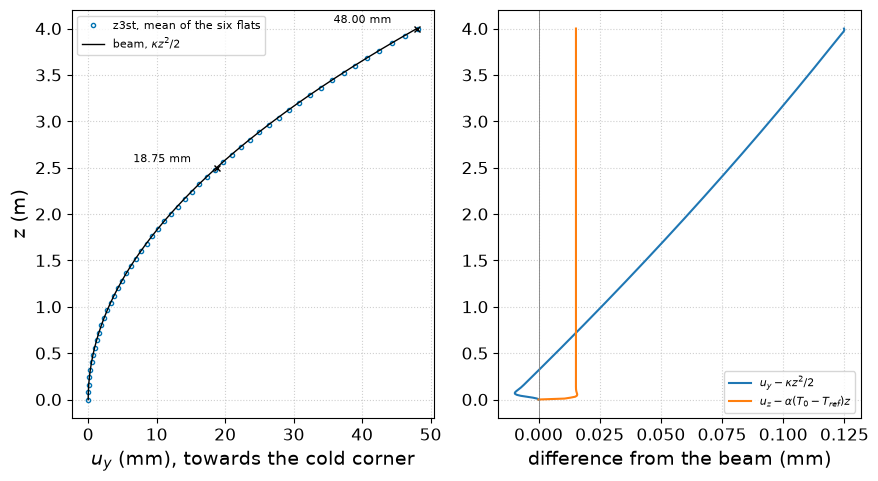

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 5))
zz = np.linspace(0, H, 201)
ax = axes[0]
ax.plot(uy_vtb[::8] * 1e3, zs[::8], "o", ms=3, mfc="none", label="z3st, mean of the six flats")
ax.plot(w(zz) * 1e3, zz, "k-", lw=1, label=r"beam, $\kappa z^2/2$")
for z in (2.5, H):
    ax.plot(w(z) * 1e3, z, "kx")
    ax.annotate(f"{w(z) * 1e3:.2f} mm", (w(z) * 1e3, z), xytext=(-60, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel(r"$u_y$ (mm), towards the cold corner"); ax.set_ylabel("z (m)")
ax.grid(ls=":", alpha=0.6); ax.legend(fontsize=8)
ax = axes[1]
ax.plot((uy_vtb - w(zs)) * 1e3, zs, "-", color="tab:blue", label=r"$u_y - \kappa z^2/2$")
ax.plot((uz_all - ALPHA * (525 - T_REF) * zs) * 1e3, zs, "-", color="tab:orange", label=r"$u_z - \alpha(T_0 - T_{ref})z$")
ax.axvline(0, color="gray", lw=0.6)
ax.set_xlabel("difference from the beam (mm)"); ax.grid(ls=":", alpha=0.6); ax.legend(fontsize=8)
fig.tight_layout()

**Recorded.**

| | closed form | z3st | |
|---|---|---|---|
| curvature $\kappa$ (1/m), fit $z > 0.5$ m | $6.000\cdot10^{-3}$ | $5.998\cdot10^{-3}$ | −0.04 % |
| deflection at 1.0 m | 3.00 mm | 3.03 mm | +0.9 % |
| deflection at 2.5 m | 18.75 mm | 18.83 mm | +0.4 % |
| deflection at the tip (4 m) | 48.00 mm | 48.12 mm | +0.26 % |
| elongation $\Delta H$ | 9.00 mm | 9.015 mm | +0.17 % |
| VTB centre vs section mean | | ≤ 1.9 µm | |
| $u_x$ of the centre | 0 | < 0.01 µm | |

The curvature matches the beam value to 0.04 %, so with 10 mm elements the parasitic shear of the Q1 hexahedra is
negligible here. The small excess in deflection is not a curvature error. Above 0.5 m, $u_y$ is
$\kappa z^2/2 + \theta_0 z + w_0$ with $\theta_0 \approx 3.9\cdot10^{-5}$ rad and $w_0 \approx -0.01$ mm: the base
zone adds a small rigid rotation. The clamp holds the hot side of the bottom section more firmly in its plane, and
through Poisson this shortens the base cells unevenly ($\sigma_{zz}$ = +53 / +63 / +72 MPa in the first layer, cold
→ hot). $\theta_0 H$ = 0.16 mm accounts for the tip excess. The 15 µm excess in $\Delta H$ has the same origin.

## 4. The analytical solution in detail

Sections 1–3 used three closed-form results: a linear $T$ is stress-free, the duct bows like a beam with
$\kappa = \alpha\,\Delta T/D$, and the clamp disturbs only a short base zone. This section derives them from the
three scales of the wrapper (wall as a plate, section as a closed ring, duct as a beam), lists the section
properties, and adds exact identities that hold inside the base zone too, where the stress field itself has no
closed form. The inner–outer (through-wall) gradient, absent in VP1, is summarised in 4.3 because it superposes on
the bow; its slab derivation is in `../Exercise - Thermal stress in hexagone- flats.ipynb`.

### 4.1 Which temperature fields are stress-free

The thermal strain is the isotropic eigenstrain $\theta\,\mathbf I$, with $\theta = \alpha\,(T - T_{ref})$. A free
body is stress-free only if this strain is compatible, i.e. derives from a continuous displacement. Inserting
$\varepsilon_{ij} = \theta\,\delta_{ij}$ in the Saint-Venant compatibility equations
$$\varepsilon_{ij,kl} + \varepsilon_{kl,ij} - \varepsilon_{ik,jl} - \varepsilon_{jl,ik} = 0$$
and contracting one pair of indices gives, in 3D,
$$\theta_{,ij} = 0 \qquad \text{for all } i, j:$$
a free body is stress-free if and only if $T$ is linear in $(x, y, z)$. For $T - T_{ref} = \theta_0 + \mathbf b\cdot\mathbf x$
the displacement that accommodates it is
$$\mathbf u = \alpha\Big[(\theta_0 + \mathbf b\cdot\mathbf x)\,\mathbf x - \tfrac12\,|\mathbf x|^2\,\mathbf b\Big]
\qquad (+\ \text{rigid motion}),$$
whose symmetric gradient is exactly $\alpha\,(T - T_{ref})\,\mathbf I$. It is a polynomial, hence single-valued
around the hole of the duct as well: the hollow section adds no constraint.

For VP1, $\theta_0 = T_0 - T_{ref} = 125$ K and $\mathbf b = (0,\ c_y,\ 0)$ with $c_y = -333.3$ K/m:
$$u_x = \alpha\,(\theta_0 + c_y y)\,x, \qquad
u_y = \alpha\Big[\theta_0\,y + \tfrac12\,c_y\,(y^2 - x^2)\Big] - \tfrac12\,\alpha\,c_y\,z^2, \qquad
u_z = \alpha\,(\theta_0 + c_y y)\,z .$$

* On the axis $u_y = \kappa z^2/2$ with $\kappa = -\alpha c_y$, and $u_z = \alpha\theta_0 z - \kappa\,y\,z$: the beam
  kinematics of section 1, here an exact 3D field rather than an assumption.
* In the section plane every point dilates by $\alpha\,(T - T_{ref})$, more on the hot side, and each flat takes the
  free curvature of the through-wall component of the gradient, $\alpha\,c_y\,n_y$ (a sag of about 4 µm over a
  flat). The section changes shape slightly, without stress.
* At $z = 0$ the field gives $u_z = 0$ and $\partial u_y/\partial z = 0$, as the clamp requires, but $u_x, u_y \neq 0$,
  up to 0.15 mm at the corners. `Clamp_x` and `Clamp_y` cancel exactly this in-plane dilation. It is the only source
  of stress in the duct, which is why the stress of section 2 is confined to the base.

**2D is different.** In a plane problem compatibility reduces to one equation, $\nabla^2\theta = 0$, and in a hollow
section the rotation must also be single-valued around the hole (Dundurs' theorem). A harmonic $T$ is then
stress-free in a simply connected section, but not in the closed hexagon if heat flows through the hole. That is the
mechanism of the inner–outer gradient (4.3), not of VP1.

### 4.2 Section properties and beam bending

| | formula | VP1 |
|---|---|---|
| outer / inner circumradius | $R_o$, $R_i = R_o - 2t/\sqrt3$ | 76.73 / 73.27 mm |
| flat length at mid-wall | $L = (R_i + R_o)/2$ | 75.00 mm ($D = 2L$) |
| mid-wall apothem | $a = L\cos 30^\circ$ | 64.95 mm |
| area | $A = 6Lt$ | $1.350\cdot10^{-3}$ m² |
| second moment, any axis | $I = \tfrac52\,L^3 t$ | $3.164\cdot10^{-6}$ m⁴ |
| bending stiffness | $EI$ | $5.38\cdot10^{5}$ N m² |

$I$ is the same for every bending direction: a second-moment tensor invariant under 60° rotations is isotropic.
For bending towards a corner, as in VP1, the two flats parallel to $y$ give $2 \cdot L^3 t/12$ and the four inclined
ones $4 \cdot \tfrac{7}{12} L^3 t$, total $\tfrac52 L^3 t$ (exact hollow hexagon: $3.166\cdot10^{-6}$ m⁴).

**General temperature.** For any $T(x, y)$ in a free beam, plane sections give
$$\varepsilon_0 = \alpha\,(\langle T\rangle - T_{ref}), \qquad \kappa = -\frac{\alpha}{I}\int_A T\,y\,dA, \qquad
\sigma_{zz} = -E\alpha\,\big(T - T_{plane}\big), \quad T_{plane} = \langle T\rangle - \frac{\kappa}{\alpha}\,y ,$$
with $\kappa$ positive towards $+y$ as in section 1. For VP1 $\int T y\,dA = c_y I$, so
$\kappa = -\alpha c_y = \alpha\,\Delta T/D$ and $T = T_{plane}$.

**Orientation.** $\kappa$ depends on the gradient vector only. What the orientation changes is the definition of
$\Delta T$ (corner to corner the distance is $D = 2L$ = 0.150 m, flat to flat $2a$ = 0.130 m: the same gradient gives
50 K and 43.3 K) and the extreme fibre of restrained bending (the corners at $R_o$ rather than the flats at
$R_o\cos30^\circ$: a factor 1.155).

**Supports.** The elastic line is $w'' = \kappa_T(z) - M(z)/EI$, with $w$ towards the cold corner and $M$ the moment
of the external reactions:

| supports | deflection | stress |
|---|---|---|
| base clamped, top free (VP1) | $w = \kappa z^2/2$: 48.0 mm at 4 m | 0 |
| pinned at both ends | $\kappa H^2/8$ = 12.0 mm at mid-height, towards the hot corner w.r.t. the chord | 0 |
| clamped at both ends | 0 | $M = EI\kappa$ = 3.23 kN m, $\sigma_{zz} = \pm E\kappa R_o$ = ±78.3 MPa at the corners |
| base clamped, rigid stop at the tip, gap $g$ | $F = 3EI\,(\kappa H^2/2 - g)/H^3$ | $\sigma_{zz}(0) = \pm F H R_o/I$; for $g = 0$: $F$ = 1.21 kN, ±117 MPa |

* A statically determinate support lets the duct follow its free curvature, without stress. Stress appears only
  where a redundant support prevents it.
* Restrained bowing gives a uniaxial stress, so there is no $1/(1-\nu)$ factor:
  $E\kappa R_o = \tfrac12\,E\alpha\,\Delta T\,R_o/L$. The hot side, prevented from lengthening, is in compression.
* A pad at height $z_p$ with gap $g$: $F = 3EI\,[w(z_p) - g]/z_p^3$ while $w(z_p) > g$. With several pads, superpose
  the beam influence functions and iterate on the contact status ($F_k \ge 0$).
* Step 2 (axial ramp): beam theory gives $\kappa(z) = \alpha\,\Delta T\,f(z)/D$ and
  $w(z) = \int_0^z (z - \zeta)\,\kappa(\zeta)\,d\zeta$. Inside the core, however,
  $\partial^2 T/\partial y\,\partial z = -\Delta T f'(z)/D \neq 0$, so the condition of 4.1 fails there: some stress is
  expected along the core, not only at its boundaries.

### 4.3 The cross-section as a closed ring

The section is a closed frame, three times statically indeterminate. Cut it at one point and move the three
redundants to the elastic centre O (the centre of the hexagon, by symmetry): a moment $M_0$ and a force
$\mathbf X = (X_x, X_y)$. An unloaded ring carries the same internal force at every section, $\mathbf F = -\mathbf X$
(the force on the face of normal $+\mathbf t$), and the ring moment is
$$M(s) = M_0 + X_y\,x(s) - X_x\,y(s).$$
Closing the cut (zero relative rotation and translations, Bresse's formulas) with
$\oint x\,ds = \oint y\,ds = \oint xy\,ds = 0$ and $J = \oint x^2 ds = \oint y^2 ds = \tfrac52 L^3$ decouples the three
equations:
$$M_0 = -\frac{D_b}{P}\oint\kappa_T\,ds, \qquad
X_x = \frac{D_b}{J}\Big[\oint\kappa_T\,y\,ds + \oint\varepsilon_T\,t_x\,ds\Big], \qquad
X_y = \frac{D_b}{J}\Big[-\oint\kappa_T\,x\,ds + \oint\varepsilon_T\,t_y\,ds\Big],$$
with $P = 6L$, $D_b = Et^3/[12(1-\nu^2)]$, $\varepsilon_T$ and $\kappa_T$ the free membrane strain and curvature of the
wall, and a counter-clockwise traversal.

**VP1.** With the bow free, the wall has $\varepsilon_T = \alpha\,(\theta_0 + c_y y)$ and $\kappa_T = \alpha\,c_y\,n_y$.
Then $\oint\kappa_T\,ds = \alpha c_y\oint n_y\,ds = 0$, and, since $n_y = -t_x$ on a counter-clockwise loop,
$\oint\kappa_T\,y\,ds + \oint\varepsilon_T\,t_x\,ds = \alpha c_y\big[-\oint y\,t_x\,ds + \oint y\,t_x\,ds\big] = 0$
(the $\theta_0$ part gives $\theta_0\oint dx = 0$); $X_y$ vanishes in the same way. So $M_0 = 0$ and $\mathbf X = \mathbf 0$:
no ring bending, as recorded in section 2 ($\sigma_{ss} \approx 0$ away from the base).

**Adding a through-wall gradient.** If heat crosses the wall (from the bundle to the inter-wrapper gap), each flat
has a linear drop $\Delta T_w$ and wants the curvature $\kappa_T^* = (1+\nu)\,\alpha\,\Delta T_w/t$ (with $\kappa_z = 0$
imposed by the tube). The ring closure no longer vanishes. The exact rotation mismatch is set by the heat crossing the
inner perimeter, $\Omega = (1+\nu)\,\alpha\,Q'/k$ with $Q' = 6\,q\,R_i$ (Dundurs), while the compliance is that of
the mid-line, $6L$:
$$M_0 = -D_b\,\kappa_T^*\,\frac{R_i}{L}, \qquad
\sigma_{ss}(\xi) = \frac{R_i}{L}\,\frac{E\alpha\,\Delta T_w}{1-\nu}\,\frac{\xi}{t}, \qquad \sigma_{nn} = 0,$$
and, for this part alone, $\sigma_{zz} = \nu\,(\sigma_{ss} + \sigma_{nn}) + E\alpha\,(\langle T\rangle_A - T)$ at every
point of the section. With the VP1 material $E\alpha/(1-\nu)$ = 4.37 MPa/K: the surface stress
$\sigma_{slab} = E\alpha\,\Delta T_w/[2(1-\nu)]$ is 2.19 MPa per kelvin of wall drop, times $R_i/L$ = 0.977. These
stresses superpose on the stress-free bow, since the problem is linear.

The plate solution fails at the corners:

* outer corner (convex, 120° of material): two free faces that are not parallel, so the in-plane stress vanishes at
  the vertex, $T = T_o$ there, and $\sigma_{zz} = E\alpha\,(\langle T\rangle_A - T_o)$;
* inner corner (re-entrant, 240°): Williams' mode I exponent $\lambda_1 = 0.6157$, so $\sigma \sim r^{\lambda_1 - 1}$ is
  singular and compressive. The FE value at the corner grows by $2^{1-\lambda_1} = 1.305$ at each halving of the
  mesh; the meaningful quantity is the notch stress intensity factor, or the peak for the real corner radius.

### 4.4 Exact identities that also hold in the base zone

The base zone has no closed-form stress field, but equilibrium still fixes integrals of it. The only loaded
surface is the clamped base $z = 0$; everything above is traction-free.

* **Section resultants.** The part of the duct above any height $z$ is load-free, so for every $z > 0$
$$N_z(z) = \int_A\sigma_{zz}\,dA = 0, \qquad M_x(z) = \int_A\sigma_{zz}\,y\,dA = 0, \qquad M_y(z) = 0 .$$
  The large base values of $\sigma_{zz}$ in section 2 (+53 / +63 / +72 MPa cold → hot in the first layer) must
  integrate to zero force and moment on every layer.
* **Volume integrals.** Since $\sigma_{ij} = \partial_k(x_i\,\sigma_{kj})$, the divergence theorem gives
  $\int_V\sigma_{ij}\,dV = \oint x_i\,t_j\,dA$ with $t_j$ the traction. Only the base carries traction, and there
  $z = 0$, hence $\int_V\sigma_{zj}\,dV = 0$ for $j = x, y, z$. The in-plane integrals $\int_V\sigma_{xx}\,dV$ and
  $\int_V\sigma_{yy}\,dV$ do not vanish: the clamp squeezes the base section.
* **Elongation.** $\int_V\varepsilon_{zz}\,dV = \int_{top}u_z\,dA$ ($u_z = 0$ at the base) and
  $\varepsilon_{zz} = [\sigma_{zz} - \nu(\sigma_{xx} + \sigma_{yy})]/E + \alpha\,(T - T_{ref})$. With
  $\int\sigma_{zz}\,dV = 0$:
$$\langle u_z\rangle_{top} = \alpha\,H\,\big(\langle T\rangle_V - T_{ref}\big) - \frac{\nu}{E\,A}\int_V(\sigma_{xx} + \sigma_{yy})\,dV .$$
  The second term is the Poisson effect of the clamp, whose compressed base cells lengthen.
* **Top rotation.** In the same way $\int_V\varepsilon_{zz}\,y\,dV = \int_{top}u_z\,y\,dA$ and
  $\int_V\sigma_{zz}\,y\,dV = \int_0^H M_x\,dz = 0$. The rotation of the top section,
  $\varphi_{top} = -\int_{top}u_z\,y\,dA\,/\,I$, is therefore
$$\varphi_{top} = \kappa H + \frac{\nu}{E\,I}\int_V(\sigma_{xx} + \sigma_{yy})\,y\,dV .$$
  The clamp squeezes the hot side harder ($\sigma_{ss} \approx -E\alpha\,(T - T_{ref})$), so the correction is
  positive: it is the extra rigid rotation that section 3 found in the fit.

The cell below evaluates each term on the stored run, with cell volumes from 2×2×2 Gauss points and the DG0 stress
at the cell centres.

In [8]:
# cell volumes of the trilinear hexahedra (2x2x2 Gauss)
g = np.array([-1.0, 1.0]) / np.sqrt(3.0)
ref = np.array([[-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1],
                [-1, -1, 1], [1, -1, 1], [1, 1, 1], [-1, 1, 1]], float)
X8 = P[TOPO]
vol = np.zeros(len(TOPO))
for a in g:
    for b in g:
        for c in g:
            dN = np.stack([ref[:, 0] * (1 + ref[:, 1] * b) * (1 + ref[:, 2] * c),
                           ref[:, 1] * (1 + ref[:, 0] * a) * (1 + ref[:, 2] * c),
                           ref[:, 2] * (1 + ref[:, 0] * a) * (1 + ref[:, 1] * b)], 1) / 8
            vol += np.abs(np.linalg.det(np.einsum("nkd,ke->nde", X8, dN)))
V = vol.sum()
A_sec = V / H                                  # (m2) cross-section area
I_sec = (vol * C[:, 1] ** 2).sum() / H         # (m4) int y^2 dA
E_MPa = E / 1e6
sig = EA * 50.0                                # (MPa) E alpha dT across the section
tr = S[:, 0, 0] + S[:, 1, 1]                   # (MPa) sigma_xx + sigma_yy per cell
print(f"A = {A_sec:.4e} m2 (6Lt = {6 * D / 2 * 0.003:.4e}),  I = {I_sec:.4e} m4 (5/2 L^3 t = {2.5 * (D / 2)**3 * 0.003:.4e})\n")

hz = zc[1] - zc[0]
print("section resultants, exact value 0:")
for z in (zc[0], zc[1], zc[3], zc[7], 0.5, H / 2, zc[-1]):
    lay_c = np.isclose(C[:, 2], zc[np.argmin(np.abs(zc - z))])
    Nz = (vol[lay_c] * S[lay_c, 2, 2]).sum() / hz
    Mx = (vol[lay_c] * S[lay_c, 2, 2] * C[lay_c, 1]).sum() / hz
    print(f"  z = {C[lay_c, 2][0]:.3f} m:  N_z / (A E a dT) = {Nz / (A_sec * sig):+.1e},"
          f"  M_x / (I/R_o E a dT) = {Mx / (I_sec / r.max() * sig):+.1e}")

Sint = np.einsum("c,cij->ij", vol, S) / (V * sig)
print("\nint sigma_ij dV / (V E a dT):  "
      f"zz {Sint[2, 2]:+.1e}, xz {Sint[0, 2]:+.1e}, yz {Sint[1, 2]:+.1e}   (exact 0);"
      f"  xx {Sint[0, 0]:+.2e}, yy {Sint[1, 1]:+.2e}   (clamp)")

top = np.isclose(P[:, 2], H)
dH_th = ALPHA * H * ((vol * T_degC(C)).sum() / V - T_REF)
dH_nu = -NU / (E_MPa * A_sec) * (vol * tr).sum()
print(f"\nelongation: alpha H (<T> - T_ref) = {dH_th * 1e3:.4f} mm,  Poisson term = {dH_nu * 1e6:+.2f} um,"
      f"  sum = {(dH_th + dH_nu) * 1e3:.4f} mm;  z3st <u_z>_top = {U[top, 2].mean() * 1e3:.4f} mm")

# top-face rotation: int_top u_z y dA over the top faces of the last cell layer (nodes 4-7 of each hexahedron)
faces = TOPO[np.isclose(C[:, 2], zc[-1])][:, 4:8]
fx = P[faces]
d1, d2 = fx[:, 2, :2] - fx[:, 0, :2], fx[:, 3, :2] - fx[:, 1, :2]
farea = 0.5 * np.abs(d1[:, 0] * d2[:, 1] - d1[:, 1] * d2[:, 0])
fy = fx[:, :, 1].mean(axis=1)
phi_top = -(farea * U[faces, 2].mean(axis=1) * fy).sum() / (farea * fy**2).sum()
th_nu = NU / (E_MPa * I_sec) * (vol * tr * C[:, 1]).sum()
th_zz = -(vol * S[:, 2, 2] * C[:, 1]).sum() / (E_MPa * I_sec)
print(f"top rotation: z3st phi_top - kappa H = {phi_top - kappa * H:.3e} rad;  Poisson term = {th_nu:.3e},"
      f"  int sigma_zz y dV term = {th_zz:+.3e} (0 in the continuum),  sum = {th_nu + th_zz:.3e}")
print(f"(phi_top - kappa H) * H = {(phi_top - kappa * H) * H * 1e3:.3f} mm,  tip excess of section 3 = "
      f"{(uy_vtb[-1] - w(H)) * 1e3:.3f} mm")

A = 1.3500e-03 m2 (6Lt = 1.3500e-03),  I = 3.1591e-06 m4 (5/2 L^3 t = 3.1641e-06)

section resultants, exact value 0:
  z = 0.005 m:  N_z / (A E a dT) = +7.2e-03,  M_x / (I/R_o E a dT) = -6.0e-03
  z = 0.015 m:  N_z / (A E a dT) = +9.8e-05,  M_x / (I/R_o E a dT) = +2.8e-04
  z = 0.035 m:  N_z / (A E a dT) = -2.0e-03,  M_x / (I/R_o E a dT) = +1.8e-03
  z = 0.075 m:  N_z / (A E a dT) = -3.1e-04,  M_x / (I/R_o E a dT) = +4.5e-04
  z = 0.495 m:  N_z / (A E a dT) = +2.2e-11,  M_x / (I/R_o E a dT) = +1.0e-04
  z = 1.995 m:  N_z / (A E a dT) = +1.5e-11,  M_x / (I/R_o E a dT) = +1.0e-04
  z = 3.995 m:  N_z / (A E a dT) = -1.2e-13,  M_x / (I/R_o E a dT) = -2.0e-04

int sigma_ij dV / (V E a dT):  zz +1.2e-11, xz -3.9e-11, yz -1.1e-08   (exact 0);  xx -7.08e-03, yy -7.08e-03   (clamp)

elongation: alpha H (<T> - T_ref) = 9.0000 mm,  Poisson term = +15.29 um,  sum = 9.0153 mm;  z3st <u_z>_top = 9.0153 mm
top rotation: z3st phi_top - kappa H = 2.991e-05 rad;  Poisson term = 3.468e-05,  int sigma_zz

**Recorded.**

| identity | exact | z3st |
|---|---|---|
| $N_z(z) / (A\,E\alpha\Delta T)$ | 0 | $7\cdot10^{-3}$ in the first cell layer, $\le 2\cdot10^{-3}$ up to 0.08 m, $\sim10^{-11}$ above |
| $M_x(z) / (I/R_o\,E\alpha\Delta T)$ | 0 | $6\cdot10^{-3}$ in the first cell layer, $\le 2\cdot10^{-3}$ up to 0.08 m, $\sim10^{-4}$ above |
| $\int\sigma_{zz}\,dV$, $\int\sigma_{xz}\,dV$, $\int\sigma_{yz}\,dV$ | 0 | $\le 10^{-8}$ of $V E\alpha\Delta T$ |
| $\int\sigma_{xx}\,dV = \int\sigma_{yy}\,dV$ | not 0 (clamp) | $-7.1\cdot10^{-3}\,V E\alpha\Delta T$ |
| elongation $\langle u_z\rangle_{top}$ | 9.0000 mm + 15.29 µm = 9.0153 mm | 9.0153 mm |
| top rotation $\varphi_{top} - \kappa H$ | Poisson term $3.47\cdot10^{-5}$ rad | $2.99\cdot10^{-5}$ rad |

* The section resultants vanish to the accuracy of the cell-centre quadrature. The residues in the first layers come
  from sampling the steep base field at one point per cell (`nt` 1), not from a lack of equilibrium.
* The elongation identity closes to the last digit: the 15 µm excess of section 3 is entirely the Poisson
  lengthening of the base cells squeezed by the clamp.
* The rotation identity closes exactly once the z3st value of $\int\sigma_{zz}\,y\,dV$ is included
  ($-0.48\cdot10^{-5}$ rad). That term is zero in the continuum; it is not zero here because Q1 elements cannot
  represent the quadratic bending mode exactly in the base cells. The rotation excess times $H$, 0.120 mm, accounts
  for the 0.125 mm tip excess of section 3.

## Open issues / next steps

1. **Base values** (σ_vm 454 MPa, σ_ss −428 MPa, σ_nn −230 MPa) come from the first cell layer with `nt` 1. They need a
   refinement through the wall and near the base before they are quoted. They do not affect the bow.
2. **Step 2**: restore the VP1 axial ramp (`Z_UNIFORM = False` in `vp1_temperature.py`, output to a new
   `output.filename`). With $f(z)$ varying across the core, $T$ is no longer a single plane along $z$: the curvature
   follows $\kappa(z) = \alpha\,\Delta T\,f(z)/D$ and the transitions at the core bottom and top bring new Saint-Venant
   zones. Inside the core $\partial^2 T/\partial y\,\partial z \neq 0$, so $T$ is no longer stress-free there (section 4.2).
3. `IAEA_VP1/gui_fields.py` reads `output/fields.xdmf`, which this case does not write: this notebook reads the
   fields directly instead.

## Summary

* $T = 525 - 333.3\,y$ °C on every section is a plane, so the duct bows and elongates without stress:
  $\kappa = \alpha\,\Delta T/D = 6.0\cdot10^{-3}$ 1/m, 48.0 mm at the tip, $\Delta H$ = 9.0 mm.
* z3st reproduces them: $\kappa$ to 0.04 %, tip 48.12 mm, $\Delta H$ 9.015 mm. The small excess is a rigid rotation
  coming from the clamped base.
* $\sigma \approx 0$ away from the base ($\sigma_{vm} \le 0.4$ MPa, Q1 residue). The clamp blocks the in-plane
  expansion of the bottom section, and $\sigma_{ss} \approx -E\alpha(T - T_{ref})$ there decays within about 0.1 m.
* Small displacements hold: $\kappa H$ = 0.024 rad, and the geometrically linear theory is off by about $5\cdot10^{-5}$.
* Section 4 derives the closed forms. In 3D a temperature is stress-free only if it is linear ($\theta_{,ij} = 0$),
  and 4.1 gives the exact displacement field; the closure of the hexagonal ring gives no section bending for a linear
  $T$. Equilibrium identities with the clamped base close the residuals of section 3: the 15 µm excess in $\Delta H$
  is $-\nu/(EA)\int(\sigma_{xx} + \sigma_{yy})\,dV$, and the extra top rotation ($3.0\cdot10^{-5}$ rad) is the same
  Poisson effect, $(\nu/EI)\int(\sigma_{xx} + \sigma_{yy})\,y\,dV$, plus a Q1 residue.